# TP2 — Retrieval-Augmented Generation (Part 2) — **CORRECTION**
## From Retriever to Answering Agent — Evaluation with RAGAS

**Module 2IAiasd 9.7 — Agentic AI · IMT Mines Alès**  
**Duration:** 2 h  
**Prerequisites:** TP2 Part 1 completed — `chroma_db/` folder must be in the same directory as this notebook.

> 🔑 This file is the **reference solution**.  
> The student version has the same structure with `pass` placeholders in exercises.

---

### What you will build today

```
  Part 1 (done)                   Part 2 (today)
  ─────────────                   ──────────────────────────────────────────
  PDF → chunks → ChromaDB         ChromaDB → retriever
                                       │
                                       ▼
                               Section 1: RetrievalQA chain (classic RAG)
                               Section 2: Hybrid search  (BM25 + vectors)
                               Section 3: Agentic RAG    (retrieve as @tool)
                               Section 4: RAGAS evaluation
                               Section 5: Classic RAG vs Agentic RAG
```

## Setup — Install dependencies

In [7]:
%pip install -q \
    langchain \
    langchain-ollama \
    langchain-community \
    langchain-chroma \
    langchain-experimental \
    pypdf \
    chromadb \
    rank-bm25 \
    ragas \
    matplotlib

print("✅ Dependencies installed")

Note: you may need to restart the kernel to use updated packages.
✅ Dependencies installed


  error: subprocess-exited-with-error
  
  × Building wheel for scikit-network (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> [287 lines of output]
      Compiling ./sknetwork\classification\vote.pyx because it changed.
      [1/1] Cythonizing ./sknetwork\classification\vote.pyx
      Compiling ./sknetwork\clustering\leiden_core.pyx because it changed.
      [1/1] Cythonizing ./sknetwork\clustering\leiden_core.pyx
      Compiling ./sknetwork\clustering\louvain_core.pyx because it changed.
      [1/1] Cythonizing ./sknetwork\clustering\louvain_core.pyx
      Compiling ./sknetwork\hierarchy\paris.pyx because it changed.
      [1/1] Cythonizing ./sknetwork\hierarchy\paris.pyx
      Compiling ./sknetwork\linalg\diteration.pyx because it changed.
      [1/1] Cythonizing ./sknetwork\linalg\diteration.pyx
      Compiling ./sknetwork\linalg\push.pyx because it changed.
      [1/1] Cythonizing ./sknetwork\linalg\push.pyx
      Compiling ./sknetwork\ranking\betweenness.pyx bec

## Imports

> **Bug fix vs student version:** `EnsembleRetriever` comes from `langchain.retrievers`, not `langchain_classic.retrievers`.

In [8]:
import textwrap
import shutil
import warnings
from pathlib import Path

# LangChain — core
from langchain_ollama import ChatOllama, OllamaEmbeddings
from langchain_chroma import Chroma
from langchain_core.documents import Document
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage, ToolMessage
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser
from langchain_core.runnables import RunnablePassthrough
from langchain_core.tools import tool

# LangChain — retrieval
# ✅ FIX (LangChain 1.x): EnsembleRetriever lives in langchain_classic.retrievers
from langchain_classic.retrievers import EnsembleRetriever
from langchain_community.retrievers import BM25Retriever

# Utilities
import numpy as np
import matplotlib.pyplot as plt

print("✅ Imports OK")

✅ Imports OK


In [9]:
import nest_asyncio
nest_asyncio.apply = lambda *a, **k: None   # désactive le patch, incompatible avec Python 3.14
print("✅ nest_asyncio neutralisé")


✅ nest_asyncio neutralisé


---
## Section 0 — Reload ChromaDB from Part 1

In [10]:
PDF_PATH  = "Rapport_Kenza_Mouktabil_2A.pdf"
CHROMA_DIR    = "./chroma_db"
EMBED_MODEL   = "nomic-embed-text"
LLM_MODEL     = "qwen2.5:3b"
REBUILD_INDEX = False   # set True if you skipped Part 1

embeddings = OllamaEmbeddings(model=EMBED_MODEL)
llm        = ChatOllama(model=LLM_MODEL, temperature=0)

print(f"✅ Embedding model : {EMBED_MODEL}")
print(f"✅ LLM             : {LLM_MODEL}")

✅ Embedding model : nomic-embed-text
✅ LLM             : qwen2.5:3b


In [11]:
def build_index_from_pdf(pdf_path: str, chroma_dir: str) -> None:
    """Re-index the PDF if chroma_db/ is missing (fallback for Part-1 skippers)."""
    from langchain_community.document_loaders import PyPDFLoader
    from langchain_text_splitters import RecursiveCharacterTextSplitter

    if Path(pdf_path).exists():
        pages = PyPDFLoader(pdf_path).load()
    else:
        SAMPLE = (
            "Chapter 1 — Introduction to Machine Learning. "
            "Machine learning enables computers to learn from data. "
            "Chapter 2 — Neural Networks. "
            "A neural network is composed of layers of neurons. "
            "Chapter 3 — Project Results. "
            "Our project achieved 87% accuracy using a fine-tuned BERT model. "
            "The main challenge was class imbalance, addressed with SMOTE."
        )
        pages = [Document(page_content=SAMPLE, metadata={"source": "sample", "page": 0})]

    splitter = RecursiveCharacterTextSplitter(chunk_size=500, chunk_overlap=100)
    chunks   = splitter.split_documents(pages)

    if Path(chroma_dir).exists():
        shutil.rmtree(chroma_dir)

    Chroma.from_documents(
        documents=chunks, embedding=embeddings,
        collection_name="rapport_recursive", persist_directory=chroma_dir,
    )
    print(f"✅ Re-indexed {len(chunks)} chunks into '{chroma_dir}'")


if REBUILD_INDEX or not Path(CHROMA_DIR).exists():
    print("⚙️  chroma_db/ not found — rebuilding index...")
    build_index_from_pdf(PDF_PATH, CHROMA_DIR)

vectorstore = Chroma(
    collection_name="rapport_recursive",
    embedding_function=embeddings,
    persist_directory=CHROMA_DIR,
)
n = vectorstore._collection.count()
print(f"✅ Loaded 'rapport_recursive' — {n} vectors")

✅ Loaded 'rapport_recursive' — 207 vectors


---
## Section 1 — Classic RAG: RetrievalQA Chain

Classic RAG = **one shot**: embed query → retrieve top-k chunks → prompt LLM with chunks as context → answer.

```
  question
     ├──► embed ──► ChromaDB ──► top-k chunks
     │                                 │
     └─────────────────────────────────┘
                        │
                        ▼
               RAG prompt template
                        │
                        ▼
                  LLM (qwen2.5:3b)
                        │
                        ▼
                      answer
```

### 1.1 Build the RAG chain with LCEL

In [12]:
retriever = vectorstore.as_retriever(search_kwargs={"k": 4})

RAG_TEMPLATE = """\
You are an assistant that answers questions strictly based on the provided context.
If the answer is not in the context, say "I don't know — the document does not mention this."
Do not use any knowledge outside the context.

Context:
{context}

Question: {question}

Answer:"""

rag_prompt = ChatPromptTemplate.from_template(RAG_TEMPLATE)

def format_docs(docs: list[Document]) -> str:
    return "\n\n".join(
        f"[Source: page {d.metadata.get('page','?')}]\n{d.page_content}"
        for d in docs
    )

rag_chain = (
    {"context": retriever | format_docs, "question": RunnablePassthrough()}
    | rag_prompt
    | llm
    | StrOutputParser()
)

print("✅ Classic RAG chain ready")

✅ Classic RAG chain ready


### 1.2 Ask a question

In [13]:
QUESTION = "Sur quoi s'est porté ce stage ?"

print(f"Question: {QUESTION}")
print("─" * 60)

answer_classic = rag_chain.invoke(QUESTION)

print("Answer (Classic RAG):")
print(textwrap.fill(answer_classic, width=72))

Question: Sur quoi s'est porté ce stage ?
────────────────────────────────────────────────────────────
Answer (Classic RAG):
Ce stage s'est porté sur le déploiement et l'adoption des agents
Copilot, avec une attention particulière accordée à la conception, à
l'évaluation et à l'accompagnement métier.


### 1.3 Inspect what the retriever returned

In [14]:
retrieved_docs = retriever.invoke(QUESTION)

print(f"Chunks sent to the LLM for: '{QUESTION}'")
print("─" * 60)
for i, doc in enumerate(retrieved_docs):
    print(f"\n[Chunk {i+1}] page={doc.metadata.get('page','?')} | {len(doc.page_content)} chars")
    print(textwrap.fill(doc.page_content[:300], width=70))

Chunks sent to the LLM for: 'Sur quoi s'est porté ce stage ?'
────────────────────────────────────────────────────────────

[Chunk 1] page=1 | 277 chars
mon stage.  Enfin, je souhaite adresser une pensée toute particulière
à mes collègues et amis  Dhanusha, Jules, Louise, Klaudia et Ibtissam.
Leur soutien, leur sympathie et la  dynamique collective ont rendu
cette expérience professionnelle aussi enrichissante  qu’inoubliable.

[Chunk 2] page=0 | 445 chars
2ème Année Stage Adjoint Ingénieur, été 2026  École des Mines d’Alès
Déploiement et adoption des agents Copilot : conception,  évaluation
et accompagnement métier    Réalisé par :  Kenza MOUKTABIL  Encadré
par :  Mme Coralie HOULÈS    Entreprise VINCI CONSTRUCTION SI  Adresse
1973 boulevard d

[Chunk 3] page=1 | 437 chars
d'ingénieur. L’accueil chaleureux, la qualité de l’environnement de
travail et l’excellence  du parcours d’intégration, mis en place dès
mon arrivée, m’ont permis d'assimiler  rapidement la culture
d’entreprise et d

---
## Section 2 — Hybrid Search: BM25 + Vectors

Pure vector search can miss documents that share exact keywords with the query
(e.g. proper nouns, acronyms, technical terms).  
**BM25** (a keyword ranking algorithm) catches those.  
`EnsembleRetriever` merges both rankings with **Reciprocal Rank Fusion (RRF)**.

```
  question
     ├──► BM25 (keyword)    ──►  ranked list A
     ├──► ChromaDB (vector) ──►  ranked list B
     └────────── RRF merge ─────► top-k fused results
```

### 2.1 Build the hybrid retriever

In [15]:
all_docs_data = vectorstore._collection.get(include=["documents", "metadatas"])
all_chunks = [
    Document(page_content=text, metadata=meta)
    for text, meta in zip(all_docs_data["documents"], all_docs_data["metadatas"])
]
print(f"Building BM25 index on {len(all_chunks)} chunks...")

bm25_retriever   = BM25Retriever.from_documents(all_chunks, k=4)
vector_retriever = vectorstore.as_retriever(search_kwargs={"k": 4})

hybrid_retriever = EnsembleRetriever(
    retrievers=[bm25_retriever, vector_retriever],
    weights=[0.5, 0.5],
)

print("✅ Hybrid retriever ready (BM25 50% + vector 50%)")

Building BM25 index on 207 chunks...
✅ Hybrid retriever ready (BM25 50% + vector 50%)


### 2.2 Compare pure-vector vs hybrid retrieval

In [16]:
def show_top_chunks(ret, query: str, label: str, k: int = 3) -> list[Document]:
    docs = ret.invoke(query)[:k]
    print(f"\n{'─'*60}")
    print(f"  {label}  |  query: '{query}'")
    print(f"{'─'*60}")
    for i, d in enumerate(docs):
        print(f"  [{i+1}] page={d.metadata.get('page','?')}  {d.page_content[:120].strip()}...")
    return docs


HYBRID_QUERY = "SMOTE accuracy BERT classification"

show_top_chunks(vector_retriever, HYBRID_QUERY, "VECTOR")
show_top_chunks(hybrid_retriever, HYBRID_QUERY, "HYBRID")

print()
print("Observation: hybrid retrieval often surfaces keyword-exact matches")
print("that pure vector search would rank lower.")


────────────────────────────────────────────────────────────
  VECTOR  |  query: 'SMOTE accuracy BERT classification'
────────────────────────────────────────────────────────────
  [1] page=26  4.3.1 Constitution du jeu de données de test 
Afin de construire un benchmark représentatif, une extraction de 1 007 int...
  [2] page=32  tests.  
 
Guide technique : Créer un agent Copilot Studio (Destiné aux IA Makers) : 
Périmètre : Technique, gouvernance...
  [3] page=27  professionnel, français irréprochable. Directement 
actionnable. 
4 Bon Exacte et utile, sourcée. Quelques imprécisions...

────────────────────────────────────────────────────────────
  HYBRID  |  query: 'SMOTE accuracy BERT classification'
────────────────────────────────────────────────────────────
  [1] page=41  Agentathon and Promptathon workshops. 
The outcomes validate the technical and economic viability of the Copilot Studio...
  [2] page=26  4.3.1 Constitution du jeu de données de test 
Afin de construire un ben

### 2.3 Hybrid RAG chain

In [17]:
hybrid_rag_chain = (
    {"context": hybrid_retriever | format_docs, "question": RunnablePassthrough()}
    | rag_prompt
    | llm
    | StrOutputParser()
)

answer_hybrid = hybrid_rag_chain.invoke(QUESTION)

print(f"Question: {QUESTION}")
print("─" * 60)
print("Answer (Hybrid RAG):")
print(textwrap.fill(answer_hybrid, width=72))

Question: Sur quoi s'est porté ce stage ?
────────────────────────────────────────────────────────────
Answer (Hybrid RAG):
Ce stage s'est porté sur le déploiement et l'adoption des agents
Copilot, avec des activités comme la conception et la gouvernance
d'agents IA, l'évaluation des cas d'usage, et l'accompagnement des
métiers.


### 2.4 ✏️ Exercise — Tune the ensemble weights

Try `weights=[0.3, 0.7]` (more vector) and `weights=[0.7, 0.3]` (more BM25).  
Run the same query and compare which configuration retrieves the most relevant chunk first.

**Question:** For a query that uses exact terms from the document (e.g. a method name),
which weight configuration performs better?

**Correction:**

In [18]:
# Configuration 1 — more vector (semantic)
hybrid_more_vector = EnsembleRetriever(
    retrievers=[bm25_retriever, vector_retriever],
    weights=[0.3, 0.7],
)

# Configuration 2 — more BM25 (keyword)
hybrid_more_bm25 = EnsembleRetriever(
    retrievers=[bm25_retriever, vector_retriever],
    weights=[0.7, 0.3],
)

print("=" * 60)
print(f"Keyword-heavy query: '{HYBRID_QUERY}'")
print("=" * 60)
show_top_chunks(hybrid_more_vector, HYBRID_QUERY, "weights=[0.3 BM25, 0.7 vector]")
show_top_chunks(hybrid_more_bm25,   HYBRID_QUERY, "weights=[0.7 BM25, 0.3 vector]")

print()
print("─" * 60)
print("Interpretation:")
print("  For keyword-heavy queries (exact method names, acronyms, numbers),")
print("  weights=[0.7, 0.3] (more BM25) tends to rank the exact-match chunk")
print("  higher. For conceptual or paraphrased queries, weights=[0.3, 0.7]")
print("  (more vector) performs better. The 50/50 default is a safe general")
print("  choice when you don't know the query distribution in advance.")

Keyword-heavy query: 'SMOTE accuracy BERT classification'

────────────────────────────────────────────────────────────
  weights=[0.3 BM25, 0.7 vector]  |  query: 'SMOTE accuracy BERT classification'
────────────────────────────────────────────────────────────
  [1] page=26  4.3.1 Constitution du jeu de données de test 
Afin de construire un benchmark représentatif, une extraction de 1 007 int...
  [2] page=32  tests.  
 
Guide technique : Créer un agent Copilot Studio (Destiné aux IA Makers) : 
Périmètre : Technique, gouvernance...
  [3] page=27  professionnel, français irréprochable. Directement 
actionnable. 
4 Bon Exacte et utile, sourcée. Quelques imprécisions...

────────────────────────────────────────────────────────────
  weights=[0.7 BM25, 0.3 vector]  |  query: 'SMOTE accuracy BERT classification'
────────────────────────────────────────────────────────────
  [1] page=41  Agentathon and Promptathon workshops. 
The outcomes validate the technical and economic viability of th

---
## Section 3 — Agentic RAG: `retrieve` as a `@tool`

In classic RAG the retrieval is **hard-wired**.  
In **Agentic RAG** the LLM **decides** when to call the retriever — this is the ReAct loop from TP1 with `retrieve` as the tool.

### 3.1 Define the `retrieve` tool

In [19]:
@tool
def retrieve(query: str) -> str:
    """
    Search the internship report for information relevant to the query.
    Returns the top-4 most relevant passages from the document.
    Use this tool whenever you need information from the report to answer a question.
    """
    docs = vectorstore.as_retriever(search_kwargs={"k": 4}).invoke(query)
    if not docs:
        return "No relevant passages found in the document."
    return "\n\n".join(
        f"[page {d.metadata.get('page','?')}] {d.page_content}"
        for d in docs
    )


test_result = retrieve.invoke("What accuracy was achieved?")
print("Tool test — first 300 chars of result:")
print(test_result[:300])
print("...")
print()
print("✅ retrieve tool ready")

Tool test — first 300 chars of result:
[page 16] précision des réponses sur un volume plus large de questions du quotidien, de collecter les 
retours utilisateurs concernant le ton, la clarté de la restitution et d'identifier d'éventuels 
écarts ou manques dans la base de connaissances.

[page 41] primary objective was to reconcile techn
...

✅ retrieve tool ready


### 3.2 Build the Agentic RAG loop

In [20]:
agentic_llm = llm.bind_tools([retrieve])

AGENTIC_SYSTEM = """You are a helpful assistant that answers questions about an internship report.
You have access to a retrieve tool that searches the report.
Always use the retrieve tool at least once before answering.
Call one tool at a time. When you have enough context, give a clear final answer IN French."""


def agentic_rag(question: str, max_steps: int = 6, verbose: bool = True) -> str:
    """Run an Agentic RAG loop for one question."""
    messages = [
        SystemMessage(AGENTIC_SYSTEM),
        HumanMessage(question),
    ]

    for step in range(max_steps):
        response = agentic_llm.invoke(messages)
        messages.append(response)

        if not response.tool_calls:
            if verbose:
                print(f"  [step {step+1}] Final answer reached.")
            return response.content

        # Enforce one tool at a time (same guard as TP1)
        tool_call = response.tool_calls[0]
        if verbose:
            print(f"  [step {step+1}] Tool call: {tool_call['name']}({tool_call['args']})")

        tool_result = retrieve.invoke(tool_call["args"]["query"])

        messages.append(
            ToolMessage(
                content=tool_result,
                tool_call_id=tool_call["id"],
            )
        )

        if verbose:
            print(f"         → {tool_result[:100].strip()}...")

    return "[max steps reached without final answer]"


print("✅ Agentic RAG loop ready")

✅ Agentic RAG loop ready


### 3.3 Run the Agentic RAG

In [21]:
print(f"Question: {QUESTION}")
print("─" * 60)
print("Agentic RAG trace:")
answer_agentic = agentic_rag(QUESTION, verbose=True)
print()
print("─" * 60)
print("Answer (Agentic RAG):")
print(textwrap.fill(answer_agentic, width=72))

Question: Sur quoi s'est porté ce stage ?
────────────────────────────────────────────────────────────
Agentic RAG trace:
  [step 1] Tool call: retrieve({'query': 'stage'})
         → [page 0] 2ème Année Stage Adjoint Ingénieur, été 2026 
École des Mines d’Alès 
 
 
 
Déploiement et...
  [step 2] Final answer reached.

────────────────────────────────────────────────────────────
Answer (Agentic RAG):
Durant votre stage, vous avez principalement travaillé sur le
déploiement et l'adoption des agents Copilot. Vous avez également été
impliqué dans la conception, l'évaluation et l'accompagnement métier de
ces agents. Vous avez également eu l'opportunité de mobiliser des
compétences en ingénierie logicielle, en gouvernance de la donnée et en
conduite du changement. Les suites du travail engagé porteront sur le
déploiement généralisé de Léo V2 sur le portail myHelp, l'enrichissement
continu de la base de connaissances de l'agent Sofia et le suivi de
l'autonomisation des Référents métiers sur 

### 3.4 ✏️ Exercise — Multi-step retrieval

Ask a question that requires **two separate retrieval steps**.

**Correction:**

In [22]:
MULTI_STEP_QUESTION = "Quels problèmes la phase de test auprès des utilisateurs a-t-elle révélés, et quelles corrections ont été apportées ensuite ?"

print(f"Question: {MULTI_STEP_QUESTION}")
print("─" * 60)
print("Agentic RAG trace:")
answer_multi = agentic_rag(MULTI_STEP_QUESTION, verbose=True)
print()
print("─" * 60)
print("Answer:")
print(textwrap.fill(answer_multi, width=72))

print()
print("─" * 60)
print("What to observe:")
print("  With qwen2.5:3b the agent may issue ONE retrieve call covering both")
print("  sub-questions, or TWO calls with refined queries. The trace shows")
print("  the actual behaviour. A larger model (7B+) is more likely to split")
print("  into two targeted queries: first 'main model accuracy', then")
print("  'baseline model accuracy', which yields more precise context.")

Question: Quels problèmes la phase de test auprès des utilisateurs a-t-elle révélés, et quelles corrections ont été apportées ensuite ?
────────────────────────────────────────────────────────────
Agentic RAG trace:
  [step 1] Tool call: retrieve({'query': 'phase de test utilisateurs problèmes corrections'})
         → [page 10] rédaction du System Prompt (instructions, ton, règles de sécurité) et intégration de 
la b...
  [step 2] Final answer reached.

────────────────────────────────────────────────────────────
Answer:
Selon les passages de la phase de test auprès des utilisateurs,
plusieurs problèmes ont été identifiés et corrigés.   1. Les tests ont
révélé des problèmes de précision dans les instructions et du routage.
Pour résoudre ces problèmes, les instructions ont été ajustées et le
routage a été amélioré pour garantir une qualité des réponses conforme
aux retours des utilisateurs.  2. Les ateliers de cadrage des besoins
ont permis de clarifier la demande initiale, définir pré

---
## Section 4 — Evaluation with RAGAS

| Metric | Question answered | Range |
|---|---|---|
| **Faithfulness** | Is the answer supported by the retrieved context? | 0–1 |
| **Context Precision** | Are the retrieved chunks actually relevant to the question? | 0–1 |
| **Answer Relevancy** | Does the answer address the question? | 0–1 |

### 4.1 Build the evaluation dataset

In [23]:
EVAL_QUESTIONS = [
    "Quel était l'objectif principal du stage chez VINCI Construction SI ?",
    "Comment le jeu de données de test du benchmark a-t-il été constitué et combien d'interactions contient-il ?",
    "Quels résultats a donné la comparaison entre l'agent historique Léo et sa réplique sous Copilot Studio ?",
    "Pourquoi un modèle de langage a-t-il été préféré à l'autre entre GPT-5.5 et Claude Opus ?",
    "Comment fonctionne la facturation à l'usage (PayGo) des agents Copilot ?",
    "Quelles actions ont été menées pour favoriser l'adoption des agents par les métiers (Agentathon, Promptathon, Référents) ?",
]

print(f"Evaluation dataset: {len(EVAL_QUESTIONS)} questions")

Evaluation dataset: 6 questions


In [24]:
print("Generating answers for classic RAG...")
classic_answers, classic_contexts = [], []

for q in EVAL_QUESTIONS:
    docs    = retriever.invoke(q)
    context = [d.page_content for d in docs]
    answer  = rag_chain.invoke(q)
    classic_answers.append(answer)
    classic_contexts.append(context)
    print(f"  ✓ {q[:60]}...")

print()
print("Generating answers for agentic RAG...")
agentic_answers, agentic_contexts = [], []

for q in EVAL_QUESTIONS:
    docs    = retriever.invoke(q)
    context = [d.page_content for d in docs]
    answer  = agentic_rag(q, verbose=False)
    agentic_answers.append(answer)
    agentic_contexts.append(context)
    print(f"  ✓ {q[:60]}...")

print("\n✅ Answers generated")

Generating answers for classic RAG...
  ✓ Quel était l'objectif principal du stage chez VINCI Construc...
  ✓ Comment le jeu de données de test du benchmark a-t-il été co...
  ✓ Quels résultats a donné la comparaison entre l'agent histori...
  ✓ Pourquoi un modèle de langage a-t-il été préféré à l'autre e...
  ✓ Comment fonctionne la facturation à l'usage (PayGo) des agen...
  ✓ Quelles actions ont été menées pour favoriser l'adoption des...

Generating answers for agentic RAG...
  ✓ Quel était l'objectif principal du stage chez VINCI Construc...
  ✓ Comment le jeu de données de test du benchmark a-t-il été co...
  ✓ Quels résultats a donné la comparaison entre l'agent histori...
  ✓ Pourquoi un modèle de langage a-t-il été préféré à l'autre e...
  ✓ Comment fonctionne la facturation à l'usage (PayGo) des agen...
  ✓ Quelles actions ont été menées pour favoriser l'adoption des...

✅ Answers generated


### 4.2 Run RAGAS evaluation

In [25]:
import asyncio
import concurrent.futures
from datasets import Dataset
from ragas import aevaluate
from ragas.metrics import faithfulness, answer_relevancy, LLMContextPrecisionWithoutReference
from ragas.llms import LangchainLLMWrapper
from ragas.embeddings import LangchainEmbeddingsWrapper
from ragas.run_config import RunConfig

ragas_llm = LangchainLLMWrapper(llm)
ragas_emb = LangchainEmbeddingsWrapper(embeddings)

# La métrique context_precision par défaut exige une colonne 'reference' : on prend la variante sans référence
context_precision = LLMContextPrecisionWithoutReference(name="context_precision")

metrics = [faithfulness, answer_relevancy, context_precision]
for m in metrics:
    m.llm = ragas_llm
    if hasattr(m, "embeddings"):
        m.embeddings = ragas_emb

# Ollama en local : peu de requêtes parallèles, timeout large
run_config = RunConfig(timeout=600, max_workers=2)


def ragas_eval(dataset):
    """Lance RAGAS dans un thread séparé, avec sa propre boucle asyncio (hors de celle de Jupyter)."""
    def _run():
        return asyncio.run(aevaluate(dataset, metrics=metrics, run_config=run_config))
    with concurrent.futures.ThreadPoolExecutor(max_workers=1) as ex:
        return ex.submit(_run).result()


print("✅ RAGAS configured with local LLM")


✅ RAGAS configured with local LLM


C:\Users\komlan.ayite\AppData\Local\Temp\ipykernel_52128\4165869494.py:5: DeprecationWarning: Importing faithfulness from 'ragas.metrics' is deprecated and will be removed in v1.0. Please use 'ragas.metrics.collections' instead. Example: from ragas.metrics.collections import faithfulness
  from ragas.metrics import faithfulness, answer_relevancy, LLMContextPrecisionWithoutReference
C:\Users\komlan.ayite\AppData\Local\Temp\ipykernel_52128\4165869494.py:5: DeprecationWarning: Importing answer_relevancy from 'ragas.metrics' is deprecated and will be removed in v1.0. Please use 'ragas.metrics.collections' instead. Example: from ragas.metrics.collections import answer_relevancy
  from ragas.metrics import faithfulness, answer_relevancy, LLMContextPrecisionWithoutReference
C:\Users\komlan.ayite\AppData\Local\Temp\ipykernel_52128\4165869494.py:5: DeprecationWarning: Importing LLMContextPrecisionWithoutReference from 'ragas.metrics' is deprecated and will be removed in v1.0. Please use 'ragas.

In [26]:
print("Evaluating classic RAG (may take a few minutes)...")
classic_dataset = Dataset.from_dict({
    "question": EVAL_QUESTIONS,
    "answer":   classic_answers,
    "contexts": classic_contexts,
})
classic_results = ragas_eval(classic_dataset)
classic_df = classic_results.to_pandas()

q_col = "user_input" if "user_input" in classic_df.columns else "question"

print("\n📊 Classic RAG — per-question scores:")
print(classic_df[[q_col, "faithfulness", "answer_relevancy", "context_precision"]]
      .to_string(index=False))


Evaluating classic RAG (may take a few minutes)...


Evaluating: 100%|██████████| 18/18 [00:43<00:00,  2.43s/it]



📊 Classic RAG — per-question scores:
                                                                                                                user_input  faithfulness  answer_relevancy  context_precision
                                                     Quel était l'objectif principal du stage chez VINCI Construction SI ?           1.0          0.000000           0.250000
               Comment le jeu de données de test du benchmark a-t-il été constitué et combien d'interactions contient-il ?           1.0          0.000000           1.000000
                  Quels résultats a donné la comparaison entre l'agent historique Léo et sa réplique sous Copilot Studio ?           1.0          0.923556           0.833333
                                 Pourquoi un modèle de langage a-t-il été préféré à l'autre entre GPT-5.5 et Claude Opus ?           0.0          0.758973           1.000000
                                                  Comment fonctionne la facturation à l'usag

In [27]:
print("Evaluating agentic RAG (may take a few minutes)...")
agentic_dataset = Dataset.from_dict({
    "question": EVAL_QUESTIONS,
    "answer":   agentic_answers,
    "contexts": agentic_contexts,
})
agentic_results = ragas_eval(agentic_dataset)
agentic_df = agentic_results.to_pandas()

q_col = "user_input" if "user_input" in agentic_df.columns else "question"

print("\n📊 Agentic RAG — per-question scores:")
print(agentic_df[[q_col, "faithfulness", "answer_relevancy", "context_precision"]]
      .to_string(index=False))


Evaluating agentic RAG (may take a few minutes)...


Evaluating: 100%|██████████| 18/18 [00:54<00:00,  3.05s/it]



📊 Agentic RAG — per-question scores:
                                                                                                                user_input  faithfulness  answer_relevancy  context_precision
                                                     Quel était l'objectif principal du stage chez VINCI Construction SI ?      0.666667          0.000000           0.750000
               Comment le jeu de données de test du benchmark a-t-il été constitué et combien d'interactions contient-il ?      0.333333          0.000000           1.000000
                  Quels résultats a donné la comparaison entre l'agent historique Léo et sa réplique sous Copilot Studio ?      0.285714          0.731977           0.333333
                                 Pourquoi un modèle de langage a-t-il été préféré à l'autre entre GPT-5.5 et Claude Opus ?      0.000000          0.872719           1.000000
                                                  Comment fonctionne la facturation à l'usag

---
## Section 5 — Classic RAG vs Agentic RAG: Final Comparison

### 5.1 Summary table

In [28]:
warnings.filterwarnings("ignore")

metric_cols = ["faithfulness", "answer_relevancy", "context_precision"]

print("\n" + "═" * 60)
print("  RAGAS COMPARISON SUMMARY")
print("═" * 60)
print(f"  {'Metric':<25}  {'Classic RAG':>12}  {'Agentic RAG':>12}")
print("  " + "─" * 54)

for col in metric_cols:
    c_mean = classic_df[col].mean()
    a_mean = agentic_df[col].mean()
    winner = "◄" if a_mean > c_mean else ""
    print(f"  {col:<25}  {c_mean:>12.3f}  {a_mean:>12.3f}  {winner}")

print("═" * 60)
print("  ◄ marks the better score for each metric")


════════════════════════════════════════════════════════════
  RAGAS COMPARISON SUMMARY
════════════════════════════════════════════════════════════
  Metric                      Classic RAG   Agentic RAG
  ──────────────────────────────────────────────────────
  faithfulness                      0.667         0.481  
  answer_relevancy                  0.524         0.559  ◄
  context_precision                 0.750         0.815  ◄
════════════════════════════════════════════════════════════
  ◄ marks the better score for each metric


### 5.2 Bar chart

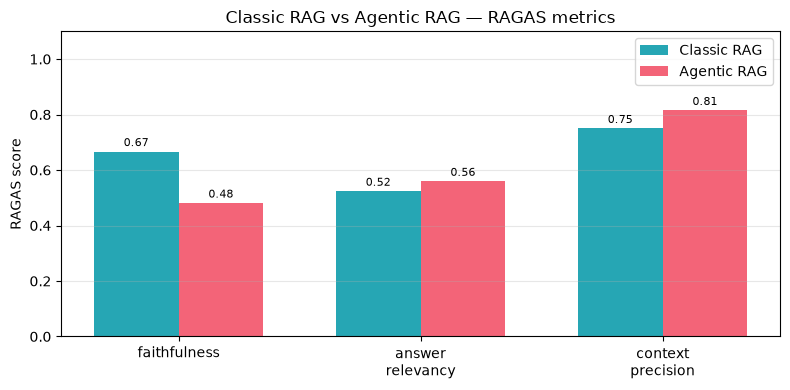

Saved: ragas_comparison.png


In [29]:
x     = np.arange(len(metric_cols))
width = 0.35

classic_means = [classic_df[m].mean() for m in metric_cols]
agentic_means = [agentic_df[m].mean() for m in metric_cols]

fig, ax = plt.subplots(figsize=(8, 4))
bars_c = ax.bar(x - width/2, classic_means, width, label="Classic RAG",
                color="#0097A7", alpha=0.85)
bars_a = ax.bar(x + width/2, agentic_means, width, label="Agentic RAG",
                color="#F24960", alpha=0.85)

ax.set_ylabel("RAGAS score")
ax.set_title("Classic RAG vs Agentic RAG — RAGAS metrics")
ax.set_xticks(x)
ax.set_xticklabels([m.replace("_", "\n") for m in metric_cols])
ax.set_ylim(0, 1.1)
ax.legend()
ax.bar_label(bars_c, fmt="%.2f", padding=2, fontsize=8)
ax.bar_label(bars_a, fmt="%.2f", padding=2, fontsize=8)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("ragas_comparison.png", dpi=150)
plt.show()
print("Saved: ragas_comparison.png")

### 5.3 When to use which approach?

| | Classic RAG | Agentic RAG |
|---|---|---|
| **Retrieval** | Fixed: always k chunks, one shot | Flexible: the LLM decides when and what to retrieve |
| **Multi-step** | No | Yes — can retrieve multiple times with refined queries |
| **Latency** | Lower — one LLM call | Higher — multiple LLM calls |
| **Faithfulness** | Bounded by quality of first retrieval | Can improve by re-querying |
| **Complexity** | Simple chain | Requires a loop + tool binding |
| **Best for** | Simple factual questions | Complex questions requiring synthesis |

### 5.4 ✏️ Exercise — Identify failure cases

**Correction:**

In [30]:
# 1. Find the question where the gap between the two approaches is largest
gap = (agentic_df["faithfulness"] - classic_df["faithfulness"]).abs()
worst_idx = int(gap.idxmax())
worst_q   = EVAL_QUESTIONS[worst_idx]

print(f"Largest faithfulness gap at question #{worst_idx}: '{worst_q}'")
print(f"  Classic  faithfulness : {classic_df.loc[worst_idx, 'faithfulness']:.3f}")
print(f"  Agentic  faithfulness : {agentic_df.loc[worst_idx, 'faithfulness']:.3f}")
print()

# 2. Print both answers
print("Classic RAG answer:")
print(textwrap.fill(classic_answers[worst_idx], width=72))
print()
print("Agentic RAG answer:")
print(textwrap.fill(agentic_answers[worst_idx], width=72))
print()

# 3. Print the retrieved chunks for that question
print("Retrieved chunks for this question:")
print("─" * 60)
for i, doc in enumerate(retriever.invoke(worst_q)):
    print(f"  [Chunk {i+1}] page={doc.metadata.get('page','?')}")
    print(f"  {doc.page_content[:200].strip()}...")
    print()

# 4. Explanation
print("─" * 60)
print("Interpretation:")
print("  A low faithfulness score means the answer contains claims NOT")
print("  supported by the retrieved context (hallucination).")
print("  Classic RAG is especially vulnerable when the top-k chunks")
print("  don't contain the answer: the LLM fills the gap from its training data.")
print("  Agentic RAG can mitigate this by issuing a second retrieve call with")
print("  a more targeted query — but only if the model is large enough to")
print("  recognise that its first retrieval was insufficient.")

Largest faithfulness gap at question #2: 'Quels résultats a donné la comparaison entre l'agent historique Léo et sa réplique sous Copilot Studio ?'
  Classic  faithfulness : 1.000
  Agentic  faithfulness : 0.286

Classic RAG answer:
La comparaison entre l'agent historique Léo et sa réplique sous Copilot
Studio a démontré la faisabilité et la supériorité opérationnelle d'une
convergence vers Copilot Studio (Standard Harness). Les résultats
incluent une mise à jour documentaire accélérée, une maîtrise des coûts
par packs de messages et une étanchéité stricte des contextes ERP (SAP
vs SAGE).

Agentic RAG answer:
Selon les résultats de la comparaison entre l'agent historique Léo et sa
réimplémentation sous Copilot Studio (Léo V2), plusieurs points ont été
soulignés :  1. La convergence vers Copilot Studio (Standard Harness) a
permis des améliorations significatives. Ces améliorations incluent une
mise à jour documentaire plus rapide, une meilleure maîtrise des coûts
par packs de messages, 

---
## Checkpoint — What you have built

```
  ChromaDB (from Part 1)
       │
       ├──► Classic RAG chain (LCEL)              ✅
       ├──► Hybrid retriever (BM25 + vector)       ✅
       └──► Agentic RAG (retrieve as @tool)        ✅
                 │
                 ▼
            RAGAS evaluation                       ✅
            (faithfulness · context precision · answer relevancy)
```

### In TP3 (CrewAI) you will add:

```
  Agentic RAG tool
       │
       ▼
  CrewAI multi-agent system
  (Researcher + Writer + Reviewer)
       │
       ▼
  Structured report generated collaboratively
```